In [22]:
import os 
import cv2
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt
from matplotlib import gridspec


matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [72]:
prefix = '/home/ruppk2@hhmi.org/tracktail-paper/renders'
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v1'

# subject = '20200709-subject-01__20200709_141754'
# subject = '20200813-subject-02__20200813_145653'
# subject = '20200820-subject-03__20200820_135841'
# subject = '20200903-subject-04__20200903_104428'
# subject = '20200908-subject-05__20200908_144409'
# subject = '20200918-subject-06__20200918_114117'
# subject = '20200928-subject-07__20200928_144906'
# subject = '20201002-subject-08__20201002_110227'
subject = '20201015-subject-09__20201015_144721'
# subject = '20201022-subject-10__20201022_112651'

video_prefixes = [
    {'Ground Truth': f'/home/ruppk2@hhmi.org/gt-renders/main_finetune_vzkjqrys_100/dex_ycb/{subject}_trial',
    'CoTracker Baseline': f'/home/ruppk2@hhmi.org/renders/cotracker-renders/paper-4cams-100/dex_ycb/test/{subject}/trial', 
    'MVTracker Baseline': f'/home/ruppk2@hhmi.org/renders/mvtracker-renders/native-4cams-duster-100/dex_ycb/{subject}_trial', 
    'Tracktail': f'/home/ruppk2@hhmi.org/posetail-renders/main_finetune_vzkjqrys_100/dex_ycb/{subject}_trial'}]

methods = list(video_prefixes[0].keys())

specs = [{
    'dataset': 'dex-ycb',
    'views': ['view_02', 'view_06'], # view_03, view_04
    'frames': [11, 23]
}]

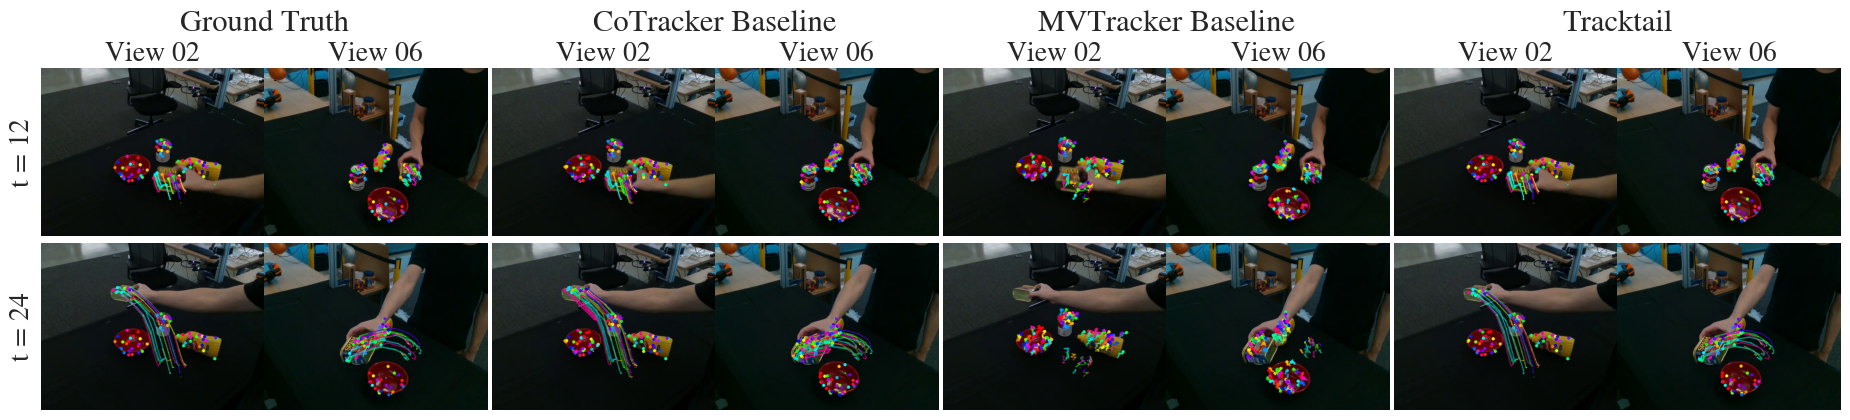

In [84]:
fs = 20
sns.set_style('ticks', {'font.family': 'STIXGeneral'})

fig = plt.figure(figsize=(20, 4.5))
gs = gridspec.GridSpec(1, 4, wspace=0.01, left=0.05, right=0.95)
gs_gt    = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0], wspace=0, hspace=0.01)
gs_left  = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[1], wspace=0, hspace=0.01)
gs_mid   = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[2], wspace=0, hspace=0.01)
gs_right = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[3], wspace=0, hspace=0.01)

axes = []
for row in range(2):
    axes.append([
        fig.add_subplot(gs_gt[row, 0]),
        fig.add_subplot(gs_gt[row, 1]),
        fig.add_subplot(gs_left[row, 0]),
        fig.add_subplot(gs_left[row, 1]),
        fig.add_subplot(gs_mid[row, 0]),
        fig.add_subplot(gs_mid[row, 1]),
        fig.add_subplot(gs_right[row, 0]),
        fig.add_subplot(gs_right[row, 1]),
    ])

for row_idx, row_axes in enumerate(axes):
    for col_idx, ax in enumerate(row_axes):

        i = col_idx % 2
        method = methods[col_idx // 2]
        view = specs[row_idx // 2]['views'][i]
        view_num = ''.join(c for c in view if c.isdigit())
        frame_num = specs[row_idx // 2]['frames'][row_idx]

        video_path = os.path.join(video_prefixes[row_idx // 2][method], f'{view}.mp4')
        cap = cv2.VideoCapture(video_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_num)
        ret, img = cap.read()
        cap.release()
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        if row_idx == 0: 
            ax.set_title(f"View {view_num}", fontsize=fs)
        if col_idx == 0:
            ax.set_ylabel(f"t = {frame_num + 1}", fontsize=fs)

for row in axes:
    for ax in row:
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.canvas.draw()
for i, method in enumerate(methods):
    ax_l = axes[0][i * 2]
    ax_r = axes[0][i * 2 + 1]
    x_center = (ax_l.get_position().x0 + ax_r.get_position().x1) / 2
    fig.text(x_center, 0.96, method, ha='center', fontsize=fs + 2, transform=fig.transFigure)
    
outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)

fig.savefig(os.path.join(outpath, 'qualitative_comparison.pdf'), dpi=800, bbox_inches='tight')
